In [ ]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

plt.style.use('ggplot')
%matplotlib inline

In [ ]:
retention = pd.read_csv('retention.csv')
retention.set_index('topic', inplace=True)
retention.columns = ['retained']
retention['lift'] = retention['retained'] / (1 - retention['retained'])

posts_per_day = pd.read_csv('posts_per_day.csv')
posts_per_day.set_index('topic', inplace=True)
posts_per_day.columns = ['posts_per_day']

dash_serves = pd.read_csv('dash_serves.csv')
dash_serves.rename(columns={'topics.topic': 'topic'}, inplace=True)
dash_serves.set_index('topic', inplace=True)
dash_serves['serves/followers'] = dash_serves['serves'] / dash_serves['followers']

engagements_per_query = pd.read_csv('engagements_per_query.csv')
engagements_per_query.set_index('query', inplace=True)

search_serves = pd.read_csv('search_serves.csv')
search_serves.set_index('query', inplace=True)
search_serves.columns = ['serves_per_search']

post_age = pd.read_csv('post_age.csv')
post_age['avg_post_age_days'] = post_age['avg_post_age'] / (60*60*24)
post_age['median_post_age_days'] = post_age['median_post_age'] / (60*60*24)

post_age_top = post_age[post_age['mode'] == 'top'][['query', 'avg_post_age_days', 'median_post_age_days']]
post_age_top.set_index('query', inplace=True)
post_age_top.columns = ['avg_post_age_top', 'median_post_age_top']
post_age_recent = post_age[post_age['mode'] == 'recent'][['query', 'avg_post_age_days', 'median_post_age_days']]
post_age_recent.set_index('query', inplace=True)
post_age_recent.columns = ['avg_post_age_recent', 'median_post_age_recent']

In [ ]:
topics = retention.join(posts_per_day).join(dash_serves).join(
    engagements_per_query).join(post_age_top).join(
    post_age_recent).join(search_serves)
topics.drop(['api-72956', 'api-72957', 'hollywoo1495683582'], inplace=True)

In [ ]:
topics.to_csv('retention_topics.csv')

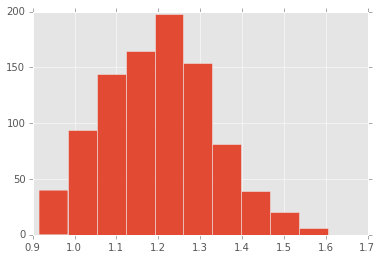

In [ ]:
topics['lift'].hist()

In [ ]:
topics.corr()['lift']

retained                  0.997235
lift                      1.000000
posts_per_day             0.059273
followers                -0.039408
serves                   -0.068967
serves/followers          0.042270
engagements_per_query     0.131705
avg_post_age_top         -0.254255
median_post_age_top      -0.239945
avg_post_age_recent      -0.167467
median_post_age_recent   -0.121653
serves_per_search         0.151329
Name: lift, dtype: float64

In [ ]:
topics[topics['posts_per_day'] < 10000].corr()['lift']

retained                  0.997240
lift                      1.000000
posts_per_day             0.151310
followers                -0.006109
serves                   -0.047535
serves/followers          0.063796
engagements_per_query     0.125116
avg_post_age_top         -0.261581
median_post_age_top      -0.246160
avg_post_age_recent      -0.167713
median_post_age_recent   -0.123946
serves_per_search         0.135476
Name: lift, dtype: float64

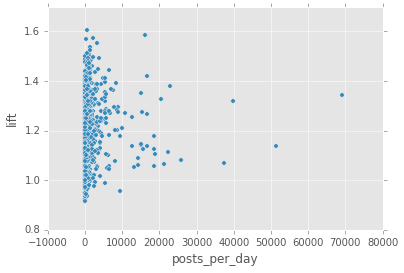

In [ ]:
topics.plot(kind='scatter', x='posts_per_day', y='lift')

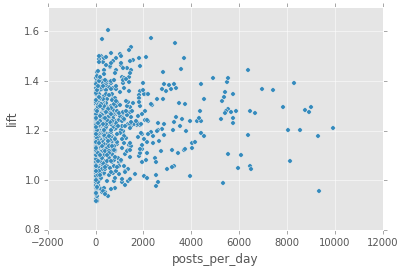

In [ ]:
topics[topics['posts_per_day'] < 10000].plot(kind='scatter', x='posts_per_day', y='lift')

In [ ]:
topics[topics['lift'] < 1].mean()

retained                      0.491302
lift                          0.966109
posts_per_day               564.708958
followers                  3979.074074
serves                    36400.888889
serves/followers              7.059838
engagements_per_query         0.276343
avg_post_age_top             57.008408
median_post_age_top          56.177229
avg_post_age_recent           6.392529
median_post_age_recent        4.668483
serves_per_search            21.963994
dtype: float64

In [ ]:
topics[topics['lift'] > 1].mean()

retained                       0.547147
lift                           1.214556
posts_per_day               1572.582382
followers                  10046.027242
serves                    142930.670829
serves/followers               8.072603
engagements_per_query          0.263384
avg_post_age_top              35.856094
median_post_age_top           32.996218
avg_post_age_recent            3.611475
median_post_age_recent         1.553879
serves_per_search             22.448528
dtype: float64

In [ ]:
topics.corr()['engagements_per_query']

retained                  0.125951
lift                      0.131705
posts_per_day             0.037213
followers                -0.040308
serves                   -0.049762
serves/followers          0.005279
engagements_per_query     1.000000
avg_post_age_top         -0.086030
median_post_age_top      -0.065488
avg_post_age_recent      -0.044102
median_post_age_recent   -0.055597
serves_per_search         0.200131
Name: engagements_per_query, dtype: float64

In [ ]:
topics.sort_values('avg_post_age_top', ascending=False)

,retained,lift,posts_per_day,followers,serves,serves/followers,engagements_per_query,avg_post_age_top,median_post_age_top,avg_post_age_recent,median_post_age_recent,serves_per_search
topic,,,,,,,,,,,,
edtech,0.544027,1.193112,147.875000,3071.0,24804.0,8.076848,0.001454,179.060993,181.680891,17.817986,9.497807,19.903846
inventions,0.555692,1.250689,21.750000,4160.0,17306.0,4.160096,0.343284,158.100758,180.344322,0.027699,0.017506,19.636364
electoral college,0.545166,1.198606,2.333333,992.0,1537.0,1.549395,1.050000,156.372661,178.645260,0.247905,0.247905,20.807692
election 2016,0.536851,1.159134,32.857143,3213.0,13442.0,4.183629,0.365079,153.550154,163.398426,0.187021,0.135631,20.732558
presidential election,0.548571,1.215190,2.142857,1128.0,2433.0,2.156915,0.272727,150.965176,160.803137,0.510532,0.510532,20.142857
video essay,0.530496,1.129909,4.000000,2450.0,6678.0,2.725714,0.082803,147.408862,167.393426,1.053501,0.669711,20.733766
hacks,0.553331,1.238794,56.714286,4527.0,2828.0,0.624696,0.142857,144.872114,182.356383,2.159322,0.031331,20.207469
economy,0.559971,1.272575,77.875000,2281.0,8154.0,3.574748,0.004158,143.818451,183.808505,9.462610,1.115052,20.023622
pauline hanson,0.535398,1.152381,1.000000,700.0,595.0,0.850000,1.644444,142.064006,182.866829,11.384248,2.787436,23.346939


In [ ]:
topics[topics['serves_per_search'] < 20]

,retained,lift,posts_per_day,followers,serves,serves/followers,engagements_per_query,avg_post_age_top,median_post_age_top,avg_post_age_recent,median_post_age_recent,serves_per_search
topic,,,,,,,,,,,,
13th,0.524470,1.102916,52.375000,1964.0,1492.0,0.759674,0.164609,65.645073,58.968287,0.050040,0.048808,19.478814
360 video,0.540157,1.174658,3.000000,3151.0,7410.0,2.351634,0.048356,125.131286,114.435278,1.576117,1.015124,18.828157
abs,0.570080,1.326012,2820.777778,7155.0,44852.0,6.268623,0.095301,3.512951,0.671928,1.891907,0.080434,15.499614
antique car,0.552124,1.232759,9.857143,2248.0,4624.0,2.056940,0.157609,21.916775,15.332137,3.520712,2.915197,14.393258
archives,0.557762,1.261224,26.250000,2987.0,11507.0,3.852360,0.013562,46.073506,42.008831,0.440718,0.123449,18.462898
asylum seekers,0.530146,1.128319,1.500000,753.0,562.0,0.746348,0.086957,38.736100,23.259489,0.014340,0.014340,13.833333
automotive,0.558151,1.263216,301.777778,3427.0,12357.0,3.605778,0.414868,48.069233,41.571829,0.129548,0.087911,19.553444
autos,0.545608,1.200744,261.500000,35103.0,1552743.0,44.233912,0.078634,30.339270,30.023868,2.132628,0.134019,19.828602
baking,0.528806,1.122266,418.666667,17277.0,62107.0,3.594779,0.143907,8.611408,5.149680,1.571143,0.307140,17.503066


In [ ]:
topics_cleaned = topics.dropna()
topics_scaled = scale(topics_cleaned)
pd.DataFrame(topics_scaled, columns=topics_cleaned.columns, index=topics_cleaned.index).corr()